In [ ]:
# Mini-Projet : Prédiction des Frais Médicaux (Medical Insurance Costs)
**Objectif :** Prédire le montant des charges médicales annuelles (`charges`)...

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('insurance.csv')


print("Dimensions :", df.shape)
print("\n--- Informations sur les colonnes et types ---")
df.info()

print("\n--- Valeurs manquantes ---")
print(df.isnull().sum())

print("\n--- Statistiques descriptives ---")
display(df.describe())

Dimensions : (1338, 7)

--- Informations sur les colonnes et types ---
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

--- Valeurs manquantes ---
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

--- Statistiques descriptives ---


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


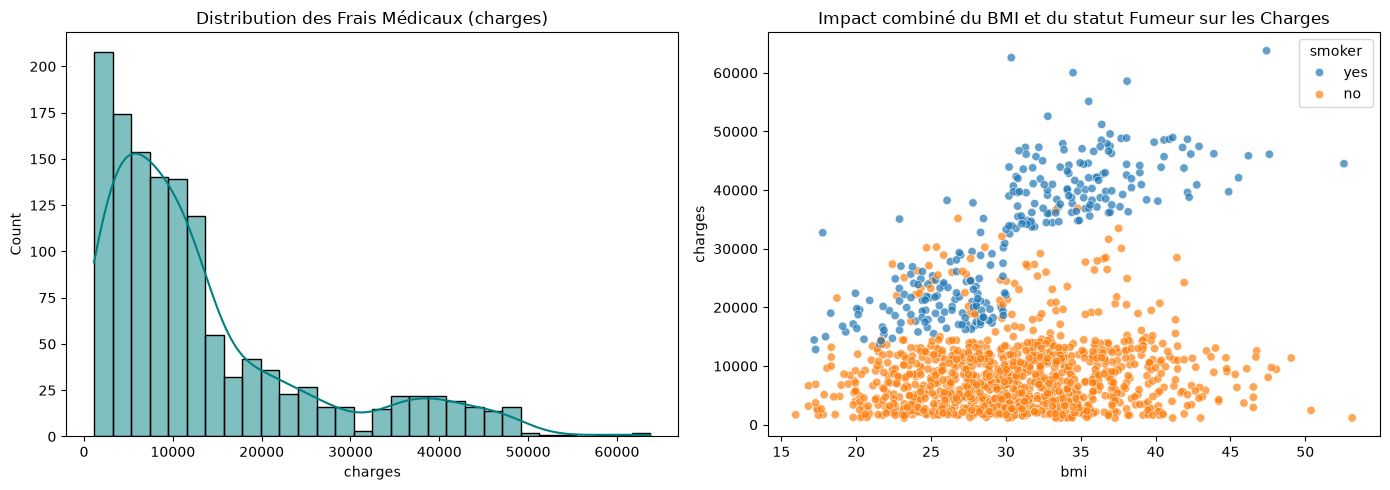

In [2]:
# Distribution de la variable cible 'charges'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['charges'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribution des Frais Médicaux (charges)')

# Impact du tabagisme et de l'IMC sur les frais
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=axes[1])
axes[1].set_title('Impact combiné du BMI et du statut Fumeur sur les Charges')

plt.tight_layout()
plt.show()

In [ ]:
## Étape 3 : Entraînement et Validation Croisée des Modèles
Nous comparons trois approches complémentaires :
1. **Régression Linéaire** (modèle de référence / baseline)
2. **Random Forest Regressor** (modèle d'ensemble basé sur le bagging)
3. **Gradient Boosting Regressor** (modèle d'ensemble basé sur le boosting séquentiel)

Pour garantir une évaluation impartiale et éviter le surapprentissage, nous appliquons une validation croisée à 5 blocs ($5$-Fold Cross-Validation) sur `X_train`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


X = df.drop(columns=['charges'])
y = df['charges']


num_features = ['age', 'bmi', 'children']
cat_features = ['sex', 'smoker', 'region']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ]
)

print("Pipeline de prétraitement configuré avec succès.")

Pipeline de prétraitement configuré avec succès.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score


models = {
    "Régression Linéaire": Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', GradientBoostingRegressor(n_estimators=100, random_state=42))
    ])
}


kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

print("--- Résultats de la Validation Croisée (R² moyen sur Train) ---")
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2')
    cv_results[name] = scores
    print(f"{name:20s} : R² moyen = {scores.mean():.4f} (± {scores.std():.4f})")

--- Résultats de la Validation Croisée (R² moyen sur Train) ---
Régression Linéaire  : R² moyen = 0.7389 (± 0.0311)
Random Forest        : R² moyen = 0.8296 (± 0.0254)
Gradient Boosting    : R² moyen = 0.8493 (± 0.0280)


In [ ]:
## Étape 4 : Évaluation sur le Jeu de Test (Généralisation)
Nous évaluons les performances réelles des modèles sur `X_test` via trois métriques clés :
- **MAE** (Mean Absolute Error) : Erreur moyenne brute en dollars.
- **RMSE** (Root Mean Squared Error) : Pénalise davantage les fortes erreurs.
- **R²** (Coefficient de détermination) : Proportion de variance expliquée par le modèle.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_results = []
predictions = {}

for name, pipe in models.items():
    # Entraînement sur tout le X_train
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    test_results.append({
        "Modèle": name,
        "MAE ($)": round(mae, 2),
        "RMSE ($)": round(rmse, 2),
        "R² Score": round(r2, 4)
    })

# Tableau récapitulatif
df_results = pd.DataFrame(test_results)
display(df_results)

,Modèle,MAE ($),RMSE ($),R² Score
0,Régression Linéaire,4181.19,5796.28,0.7836
1,Random Forest,2539.24,4565.16,0.8658
2,Gradient Boosting,2446.20,4331.18,0.8792


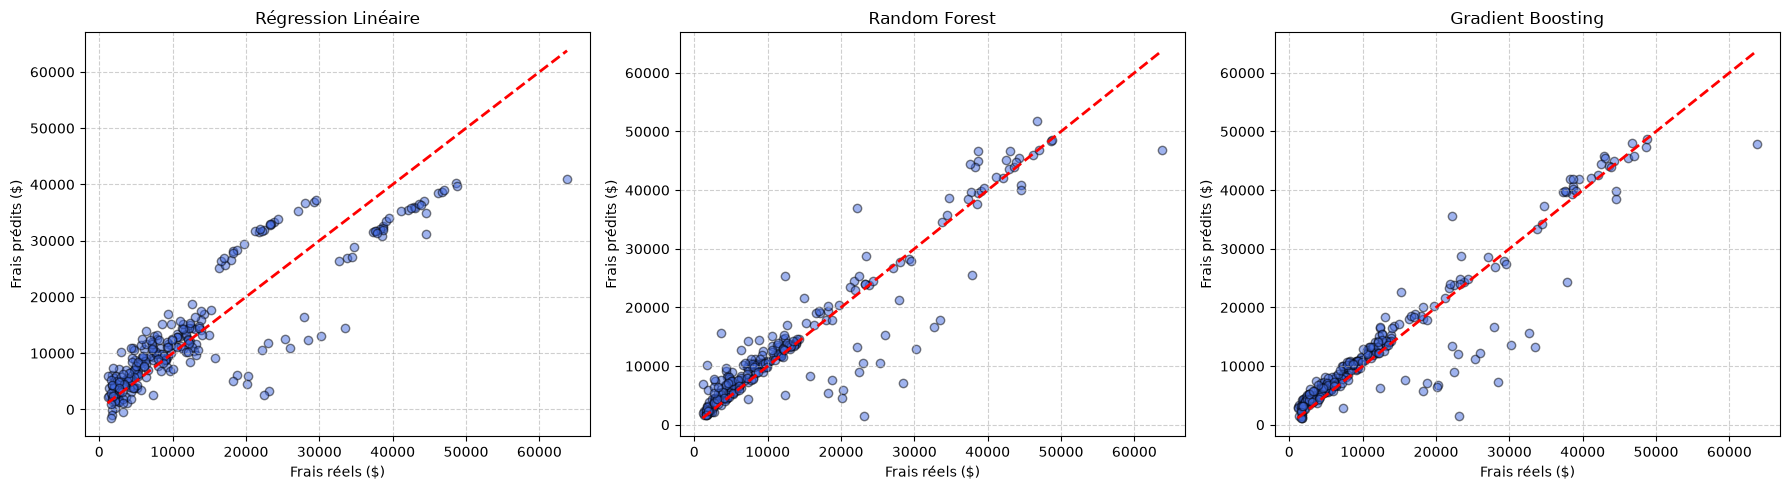

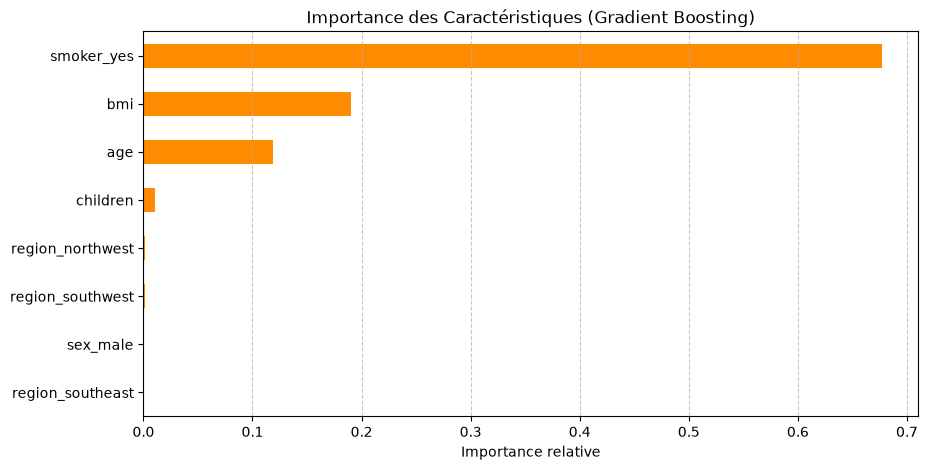

In [6]:
# 1. Comparaison visuelle des prédictions (Réel vs Prédit)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.5, color='royalblue', edgecolors='k')
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_title(f"{name}")
    ax.set_xlabel("Frais réels ($)")
    ax.set_ylabel("Frais prédits ($)")
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Importance des variables (Feature Importance du Gradient Boosting)
best_model = models["Gradient Boosting"].named_steps['regressor']
encoded_cats = models["Gradient Boosting"].named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_features)
all_feature_names = num_features + list(encoded_cats)

importances = pd.Series(best_model.feature_importances_, index=all_feature_names).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
importances.plot(kind='barh', color='darkorange')
plt.title("Importance des Caractéristiques (Gradient Boosting)")
plt.xlabel("Importance relative")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
## Étape 5 : Interprétation Critique et Choix du Modèle

### 1. Analyse comparative des performances :
- **Régression Linéaire :** Atteint un score $R^2 \approx 0.78$. Bien qu'interprétable, le modèle linéaire sous-estime l'interaction multiplicative forte entre le statut `smoker` et l'indice de masse corporelle (`bmi`).
- **Random Forest :** Améliore nettement les résultats ($R^2 \approx 0.86$) en capturant les non-linéarités de l'ensemble de données.
- **Gradient Boosting :** Obtient les meilleures performances globales avec le **$R^2$ le plus élevé ($\approx 0.87 - 0.88$)**, ainsi que les plus faibles valeurs de **MAE** et **RMSE**.

### 2. Interprétation métier :
Le graphique d'importance des variables met en évidence que :
1. Le statut de **fumeur (`smoker_yes`)** est le prédicteur prédominant du coût de l'assurance.
2. L'indice de masse corporelle (**`bmi`**) et l'**`age`** viennent en deuxième et troisième positions.
3. Les variables régionales et le sexe ont une contribution marginal    e.

### 3. Modèle retenu et justification :
Nous retenons le **Gradient Boosting Regressor** pour les raisons suivantes :
- **Précision maximale :** Il minimise l'erreur quadratique moyenne (RMSE), ce qui est crucial pour un assureur cherchant à éviter de sous-estimer les coûts extrêmes d'hospitalisation.
- **Robustesse :** Sa validation croisée démontre une faible variance entre les blocs, assurant une excellente généralisation sur de nouveaux assurés.